## **Train a Facial Recognition Model for a real time verification System**

### Install modules

In [1]:
%pip install facenet-pytorch --no-deps
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu --default-timeout=100 --resume-retries 5

Note: you may need to restart the kernel to use updated packages.
Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.


## Load dataset

In [2]:
import os
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
from torchvision import transforms as T

from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
import joblib

In [3]:
# check dataset path
def check_environment():
    """
    This function check for environment and return file path
    """
    if os.path.exists("/kaggle/working/"):
        dataset_path = Path("/kaggle/input/datasets/bodemmb230/facial-recognition/original")
        return dataset_path
    if os.path.exists("/var/colab/hostname"):
        from google.colab import drive
        drive.mount("/content/drive")
        dataset_path = Path("/content/drive/MyDrive/datasets/original")
        return dataset_path
    file_path = Path.cwd()
    return file_path / "datasets" / "original"

dataset_path = check_environment()
print(dataset_path, "exists:", dataset_path.exists())

/home/bode-murairi/Documents/programming/ml/assignments/Multimodal-Data-Preprocessing/facial_recognition/datasets/original exists: True


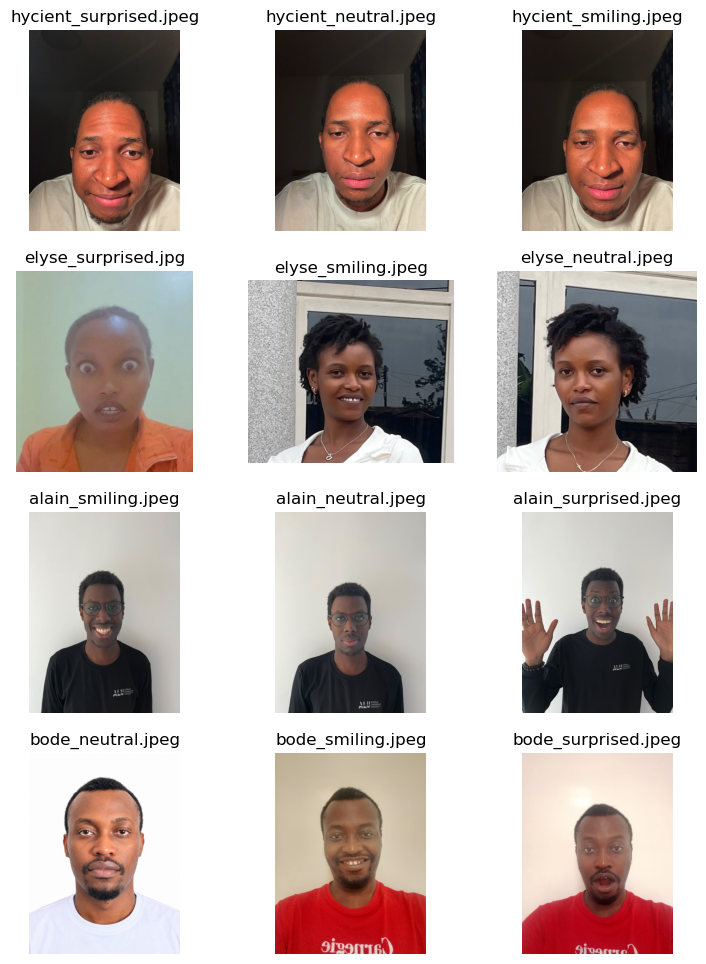

In [4]:
image_path = Path(check_environment())
files = [file for file in image_path.rglob("*") if file.is_file() and file.suffix.lower() in (".jpeg", ".jpg")]

plt.figure(figsize=(9, 3 * ((len(files) + 2) // 3)))
for i, image in enumerate(files):
    with Image.open(image) as img:
        plt.subplot((len(files) + 2) // 3, 3, i + 1)
        plt.imshow(img)
        plt.title(image.name)
        plt.axis("off")
plt.show()

## Step 1: Image Augmentation

Chain different data augmentations inside the same pipeline using **Compose** before feeding to the MTCNN.

Why apply data augmentation here before splitting the data in this case? With few images, the model needs to be trained to recognize different expressions: a cross-validation pipeline that trains on pairs of neutral/smiling, tests on surprised, then trains on neutral/surprised, tests on smiling, lastly trains on smiling/surprised, tests on neutral.

Data augmentation techniques used:

- **RandomHorizontalFlip**
- **RandomRotation**
- **RandomAffine**

Play on color to simulate different camera quality, in- and out-of-focus camera:

- **ColorJitter**
- **RandomGrayscale**
- **GaussianBlur**

In [5]:
SEED = 42
torch.manual_seed(SEED)

In [6]:
device = "cuda" if torch.cuda.is_available() else 'cpu'
print(f"Device used: {device}")
mtcnn = MTCNN(image_size=160,
              margin=20,
              keep_all=False,
              thresholds=[0.5, 0.6, 0.7],
              device=device
             )
mtcnn

Device used: cpu


MTCNN(
  (pnet): PNet(
    (conv1): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (prelu1): PReLU(num_parameters=10)
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (conv2): Conv2d(10, 16, kernel_size=(3, 3), stride=(1, 1))
    (prelu2): PReLU(num_parameters=16)
    (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (prelu3): PReLU(num_parameters=32)
    (conv4_1): Conv2d(32, 2, kernel_size=(1, 1), stride=(1, 1))
    (softmax4_1): Softmax(dim=1)
    (conv4_2): Conv2d(32, 4, kernel_size=(1, 1), stride=(1, 1))
  )
  (rnet): RNet(
    (conv1): Conv2d(3, 28, kernel_size=(3, 3), stride=(1, 1))
    (prelu1): PReLU(num_parameters=28)
    (pool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
    (conv2): Conv2d(28, 48, kernel_size=(3, 3), stride=(1, 1))
    (prelu2): PReLU(num_parameters=48)
    (pool2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
    (conv3): Conv2d(48, 64,

In [7]:
embedder = InceptionResnetV1(pretrained="vggface2").eval().to(device)

In [8]:
augs = {
    "flip": T.RandomHorizontalFlip(p=1.0),
    "rotation": T.RandomRotation(degrees=(15, 15)),
    "affine": T.RandomAffine(degrees=0, scale=(0.9, 0.9), shear=(10, 10)),
    "bright": T.ColorJitter(brightness=(1.4, 1.4), contrast=(1.3, 1.3)),
    "gray": T.Grayscale(num_output_channels=3),
    "blur": T.GaussianBlur(kernel_size=21, sigma=(3.0, 3.0)),
}

In [9]:
def save_augmented_image(augmented_image,
                         image: Path,
                         aug_name: str,
                         output_root: Path) -> Path:
    """
    This function saves an augmented image to output_root/<person>/<stem>_<aug_name>.jpeg
    """
    person_folder = output_root / image.parent.name
    person_folder.mkdir(parents=True, exist_ok=True)
    save_path = person_folder / f"{image.stem}_{aug_name}.jpeg"
    augmented_image.save(save_path, "JPEG", quality=95)
    return save_path


In [10]:
def get_output_root() -> Path:
    """
    This function returns where augmented images are saved for each environment
    """
    if os.path.exists("/kaggle/working/"):
        return Path("/kaggle/working/datasets/augmented")
    if os.path.exists("/var/colab/hostname"):
        return Path("/content/drive/MyDrive/datasets/augmented")
    return Path.cwd() / "datasets" / "augmented"

output_root = get_output_root()
print(output_root)

/home/bode-murairi/Documents/programming/ml/assignments/Multimodal-Data-Preprocessing/facial_recognition/datasets/augmented


In [11]:
def apply_augmentation(images):
    """
    This function applies image augmentation then generate embedding once a face is detected
    """
    result = []
    image_augmented_path = []
    for image in images:
        img = Image.open(image).convert("RGB")
        for aug_name, augs_func in augs.items():
            augmented_image = augs_func(img)
            image_augmented_path.append(save_augmented_image(augmented_image=augmented_image,
                                                 image=image,
                                                 aug_name=aug_name,
                                                 output_root=get_output_root())) 
            face = mtcnn(augmented_image)
            if face is None:
                print(f"No face detected for: {aug_name} to {image.name} augmentation")
                continue
            with torch.no_grad():
                embed = embedder(face.unsqueeze(0).to(device))[0].cpu().numpy()
            result.append({
            "person": image.parent.name.lower(),
            "expression": image.stem.split("_")[-1],
            "is_augment":True,
            "augmentation":aug_name,
            "file": image.name,
            **{f"emb_{img_embed}": value for img_embed, value in enumerate(embed)},
        })
    return result, image_augmented_path

In [12]:
augmented_embeddings, augmented_image_paths = apply_augmentation(images=files)
print(f"Number of augmented images: {len(augmented_embeddings)} images")

Number of augmented images: 72 images


### Visualize original image

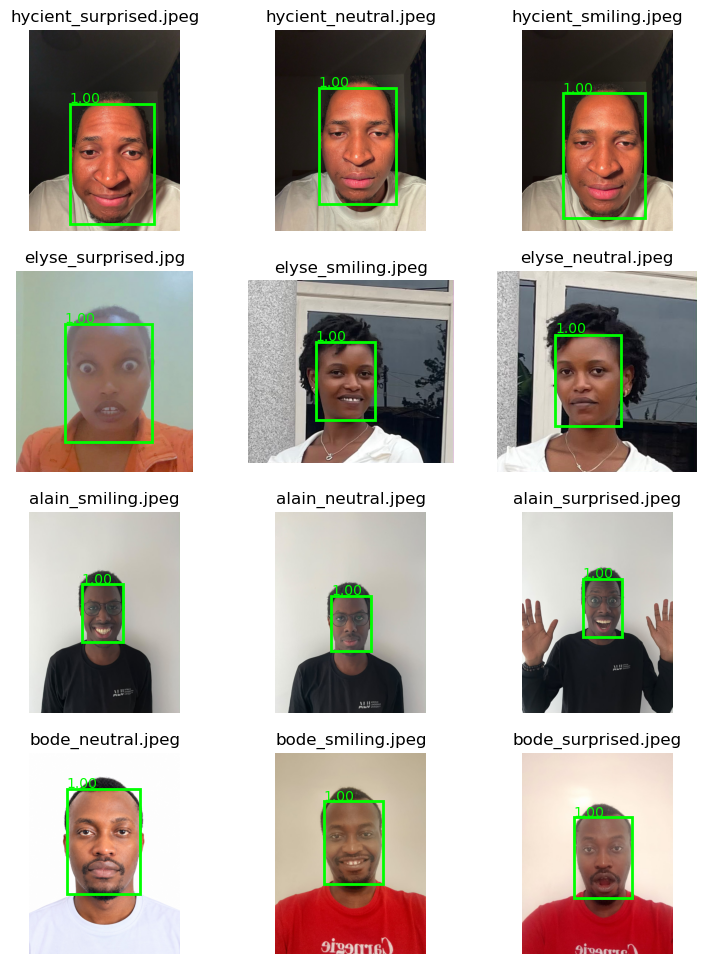

In [13]:
plt.figure(figsize=(9, 3 * ((len(files) + 2) // 3)))
result = []
for i, image in enumerate(files):
    with Image.open(image) as img:
        img = img.convert("RGB")
        boxes, probs, landmarks = mtcnn.detect(img, landmarks=True)
        plt.subplot((len(files) + 2) // 3, 3, i + 1)
        plt.imshow(img)
        if boxes is not None:
            for box, prob in zip(boxes, probs):
                x1, y1, x2, y2 = box
                plt.gca().add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                      fill=False, color="lime", linewidth=2))
                plt.text(x1, y1 - 5, f"{prob:.2f}", color="lime")
        else:
            plt.text(0.5, 0.5, "No face found", color="red",
                     ha="center", transform=plt.gca().transAxes)
        plt.title(image.name)
        plt.axis("off")
plt.show()


## Visualize sample of augmented images

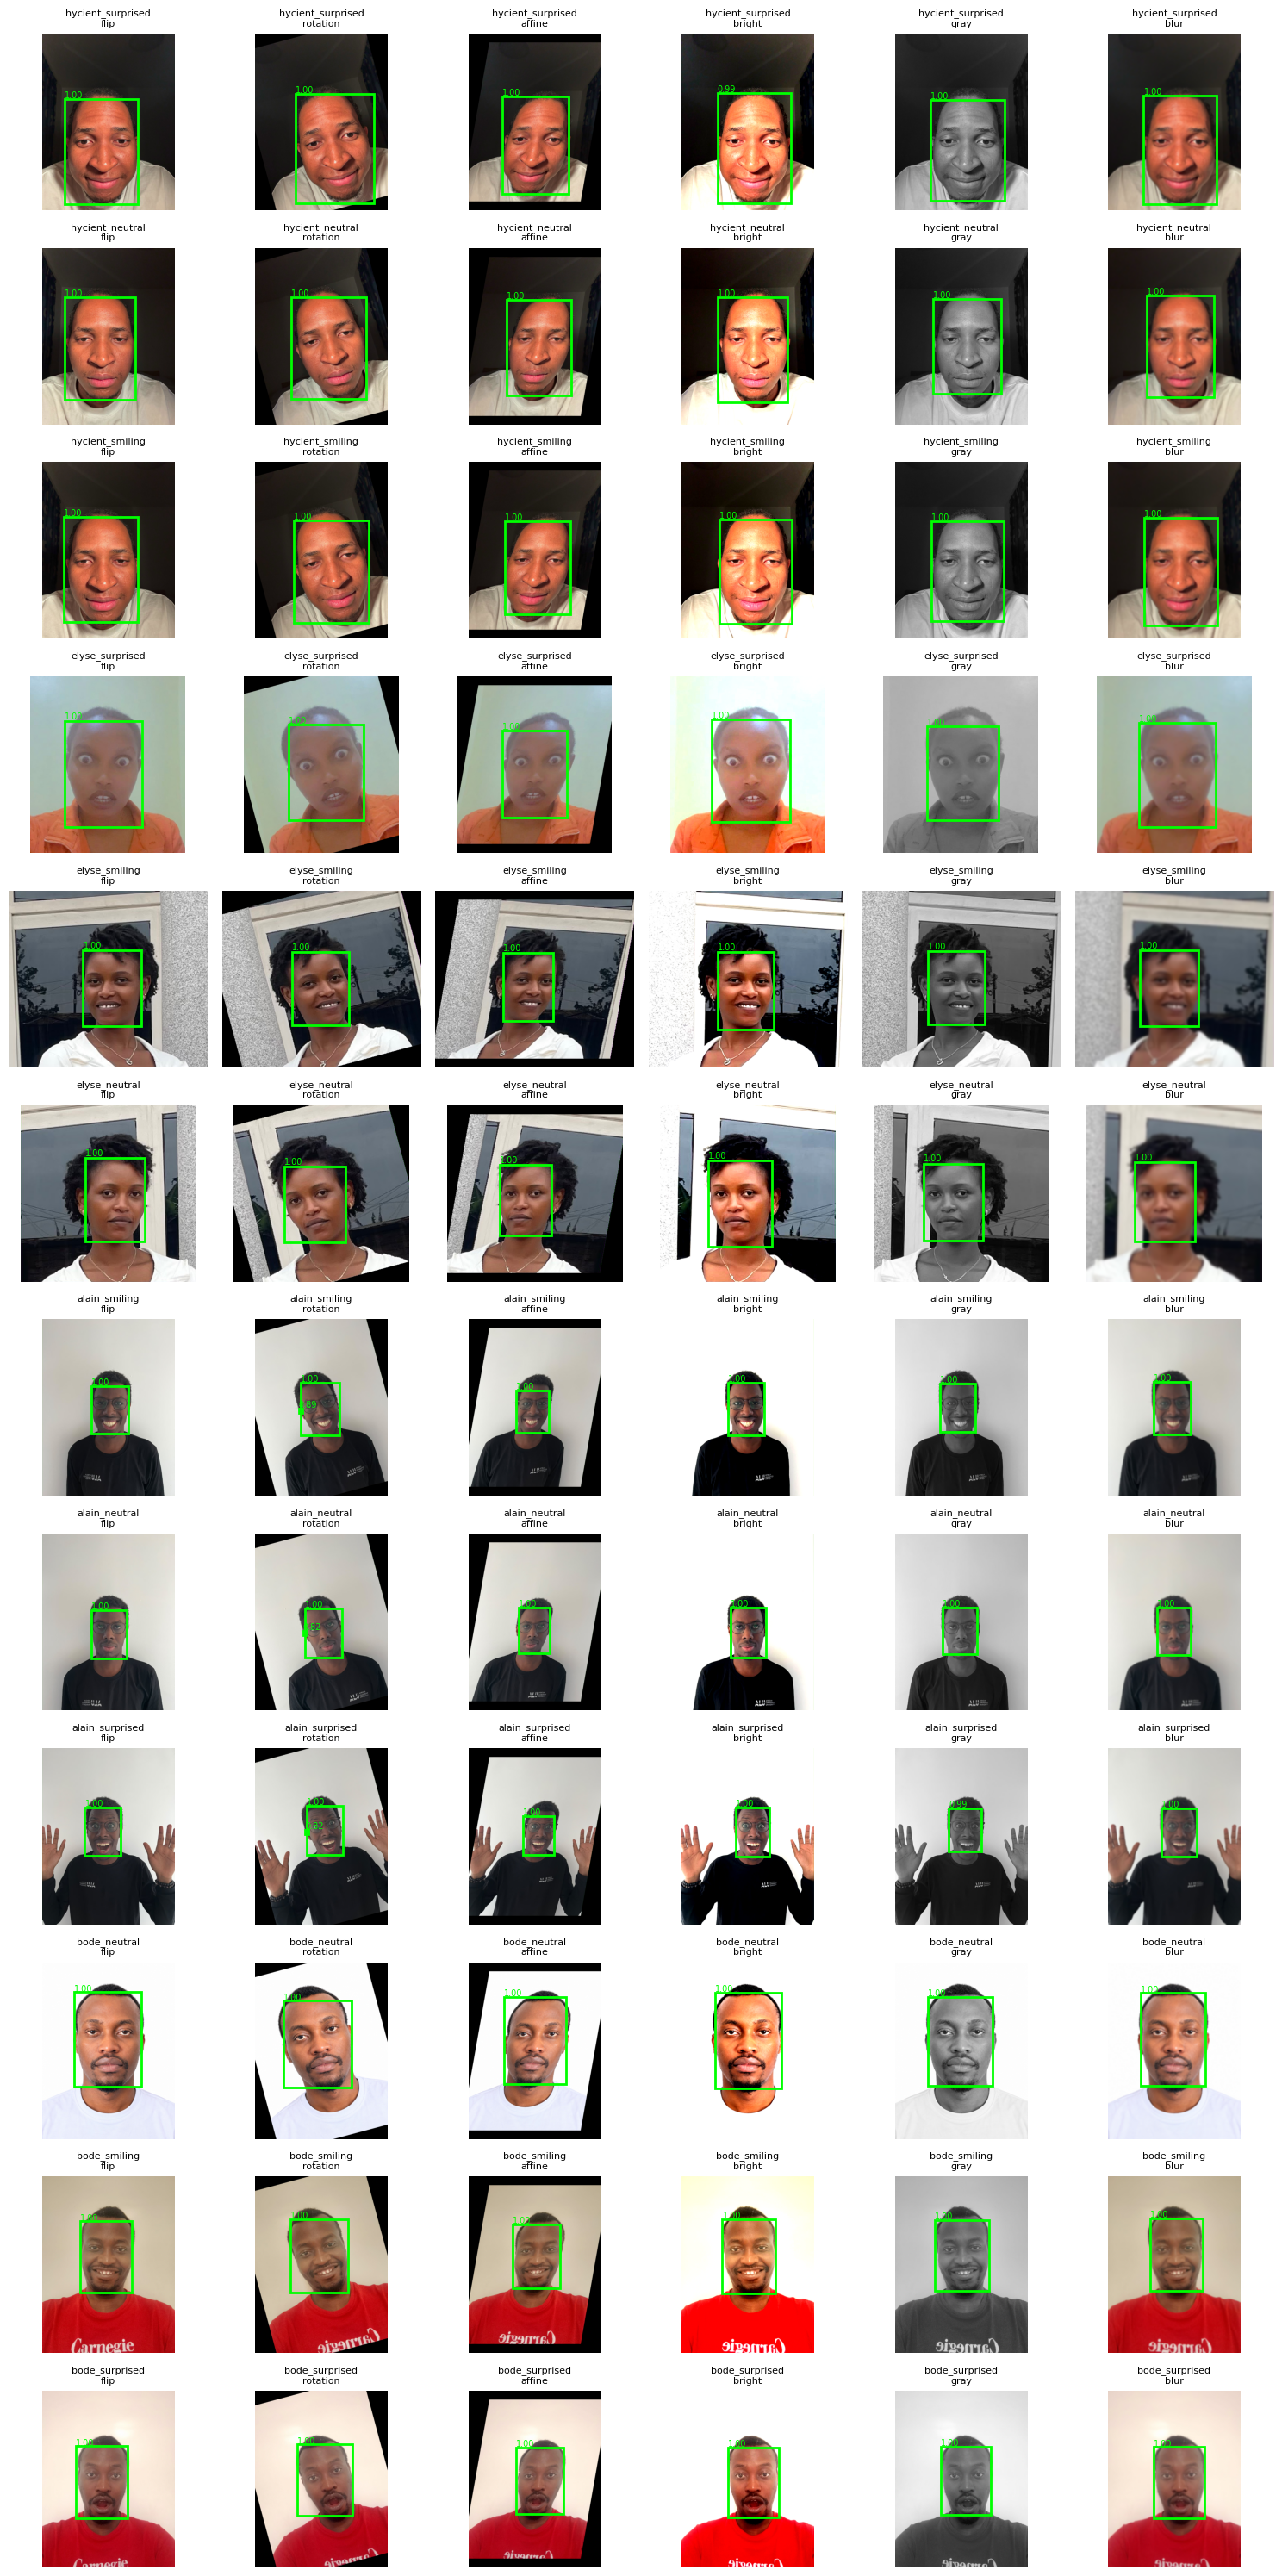

In [14]:
def show_augmentations(images, n_images=3):
    """
    This function displays every augmentation with MTCNN face detection for the first n images
    """
    n_cols = len(augs)
    plt.figure(figsize=(2.5 * n_cols, 2.5 * n_images))
    for row, image in enumerate(images[:n_images]):
        with Image.open(image) as img:
            img = img.convert("RGB")
            for col, (aug_name, aug_func) in enumerate(augs.items()):
                augmented_image = aug_func(img)
                boxes, probs = mtcnn.detect(augmented_image)
                plt.subplot(n_images, n_cols, row * n_cols + col + 1)
                plt.imshow(augmented_image)
                if boxes is not None:
                    for box, prob in zip(boxes, probs):
                        x1, y1, x2, y2 = box
                        plt.gca().add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                              fill=False, color="lime", linewidth=2))
                        plt.text(x1, y1 - 5, f"{prob:.2f}", color="lime", fontsize=7)
                else:
                    plt.text(0.5, 0.5, "No face found", color="red",
                             ha="center", transform=plt.gca().transAxes)
                plt.title(f"{image.stem}\n{aug_name}", fontsize=8)
                plt.axis("off")
    plt.tight_layout()
    plt.show()

show_augmentations(files, n_images=12)


## Step 2: Embedding images using a pretrained model
** Combine MTCNN and FaceNet**: MTCNN is used in this project to detect regions likely to have a face, while FaceNet extracts features and converts them to embeddings

In [15]:
def extract_embedding(images: list[Path]):
    """
    This function embeds all images
    """
    rows = []
    for image in images:
        img = Image.open(image).convert("RGB")
        face = mtcnn(img)
        if face is None:
            print(f"No face found for: {image.name}")
            continue
        with torch.no_grad():
            embed = embedder(face.unsqueeze(0).to(device))[0].cpu().numpy()
        rows.append({
            "person": image.parent.name.lower(),
            "expression": image.stem.split("_")[-1],
            "is_augment":False,
            "augmentation":"original",
            "file": image.name,
            **{f"emb_{img_embed}": value for img_embed, value in enumerate(embed)},
        })
    return rows

In [16]:
original_embeddings = extract_embedding(images=files)
all_embeddings = original_embeddings + augmented_embeddings
df = pd.DataFrame(all_embeddings)
df.to_csv("image_features.csv", index=False)
print(f"Shape of the image: {df.shape}")
df.head(20)

Shape of the image: (84, 517)


,person,expression,is_augment,augmentation,file,emb_0,emb_1,emb_2,emb_3,emb_4,...,emb_502,emb_503,emb_504,emb_505,emb_506,emb_507,emb_508,emb_509,emb_510,emb_511
0,hycient,surprised,False,original,hycient_surprised.jpeg,0.035407,-0.032592,-0.068730,-0.029075,0.020999,...,0.023376,-0.048592,0.059943,0.081150,-0.065492,-0.017850,-0.010802,-0.006786,0.018811,-0.045873
1,hycient,neutral,False,original,hycient_neutral.jpeg,0.026080,-0.029523,-0.090345,-0.010370,0.006661,...,0.027246,-0.039206,0.059024,0.088845,-0.036787,-0.031268,-0.006778,-0.026061,0.063824,-0.029456
2,hycient,smiling,False,original,hycient_smiling.jpeg,0.028582,-0.009587,-0.066660,-0.004599,0.024865,...,0.038364,-0.041511,0.066586,0.088712,-0.037787,-0.023722,-0.004255,-0.010734,0.037321,-0.045203
3,elyse,surprised,False,original,elyse_surprised.jpg,-0.019204,-0.078776,-0.050386,0.011092,0.058483,...,-0.049320,-0.058505,-0.006152,0.089679,0.051606,-0.002738,-0.034798,-0.054151,0.026679,-0.001346
4,elyse,smiling,False,original,elyse_smiling.jpeg,-0.082358,-0.054586,-0.104320,0.016071,0.067810,...,0.026930,-0.051779,0.051063,0.054309,0.019719,0.070403,-0.016313,0.012972,0.027304,0.006616
5,elyse,neutral,False,original,elyse_neutral.jpeg,-0.051012,-0.051406,-0.103372,0.028841,0.062202,...,0.027166,-0.058460,0.069542,0.036996,0.026572,0.067144,-0.014910,0.029218,0.064878,-0.005414
6,alain,smiling,False,original,alain_smiling.jpeg,0.041440,-0.030342,0.037357,-0.019669,-0.016453,...,-0.021258,-0.002019,0.028575,0.094770,0.038222,-0.045468,-0.052379,-0.027829,-0.033862,-0.046584
7,alain,neutral,False,original,alain_neutral.jpeg,0.045425,-0.024952,0.016895,-0.027560,-0.059236,...,-0.026275,0.017692,0.022304,0.064940,0.034860,-0.041628,-0.050473,-0.018166,-0.007904,-0.033548
8,alain,surprised,False,original,alain_surprised.jpeg,0.031548,-0.058612,0.022234,-0.014438,-0.009071,...,-0.033713,-0.014626,0.040725,0.114587,0.048610,-0.006588,-0.064041,-0.054369,-0.016246,-0.053485
9,bode,neutral,False,original,bode_neutral.jpeg,-0.009450,-0.003773,-0.044618,-0.044456,0.034271,...,-0.026123,-0.050284,0.035566,0.112593,0.011703,0.027389,-0.034990,-0.057511,0.040470,-0.036322


## Train classifiers for Identity verification
For this identity verification model with faces, we will train with SVM, Logistic regression, and KNN. FaceNet model returns vector embeddings that determine person X or Y's identity. It makes decisions using cosine similarity (lower distance means closer with each other). With few samples (50-60 training samples) and many features, a linear and distance based model would likely provide better performance compared to tree-based models (Random Forest) and boosting models.

In [17]:
X = df.filter(like="emb_").values
y = df["person"].values
groups = df["expression"].values
is_original = ~df["is_augment"].astype(bool).values
print(f"Features:\n{X[:,5]}")
print(f"Targets name:{y}")

Features:
[-0.03942911 -0.03116457 -0.01882916 -0.01259512 -0.02645253 -0.03373314
 -0.02543639 -0.01318185 -0.01469097 -0.07549699 -0.09869865 -0.08874635
 -0.04494474 -0.03942511 -0.04475123 -0.03403952 -0.02990477 -0.03944176
 -0.03831772 -0.02839343 -0.02546109 -0.02744467 -0.01897072 -0.03882474
 -0.0276063  -0.02387416 -0.01739376 -0.01754814 -0.00577829 -0.01674934
 -0.0078956  -0.01031184 -0.01375054 -0.01564599 -0.01491756 -0.00501303
 -0.03120665 -0.04297827 -0.01283116 -0.02537556 -0.04154014 -0.03789632
 -0.03325432 -0.03375279 -0.03210404 -0.0486279  -0.04460059 -0.04587152
 -0.02961179 -0.00017544 -0.03272511 -0.02915482 -0.00694604 -0.02769011
 -0.01444553 -0.01376755 -0.00419548 -0.02117825 -0.00904028 -0.00687182
 -0.0087253  -0.01550114 -0.03495695 -0.01555952  0.00365323 -0.02633027
 -0.06869759 -0.08469927 -0.08437833 -0.09074289 -0.07893033 -0.07844128
 -0.09561221 -0.077337   -0.0914434  -0.10200357 -0.08219364 -0.10383676
 -0.07124405 -0.09189165 -0.08936092 -0.0

In [18]:
models = {
    "svm": CalibratedClassifierCV(
        SVC(kernel="linear",
            C=1.0,
            random_state=SEED,
            class_weight=None),
        ensemble=False),
    "logistic_regression": LogisticRegression(max_iter=1000,
                                              C=1.0,
                                             solver="lbfgs",
                                             class_weight=None,
                                             random_state=SEED),
    "knn": KNeighborsClassifier(
        n_neighbors=3,
        metric="cosine"),
}
models

{'svm': CalibratedClassifierCV(ensemble=False,
                        estimator=SVC(kernel='linear', random_state=42)),
 'logistic_regression': LogisticRegression(max_iter=1000, random_state=42),
 'knn': KNeighborsClassifier(metric='cosine', n_neighbors=3)}

In [19]:
results = []
all_predictions = {}

In [20]:
for name, model in models.items():
    predictions = cross_val_predict(model, X, y, groups=groups, cv=LeaveOneGroupOut())
    all_predictions[name] = predictions
    results.append({
        "model":name,
        "accuracy_score":accuracy_score(y, predictions),
        "accuracy_original_photos": accuracy_score(y[is_original], predictions[is_original]),
    })
pd.DataFrame(results)

,model,accuracy_score,accuracy_original_photos
0,svm,1.0,1.0
1,logistic_regression,1.0,1.0
2,knn,1.0,1.0


	Confusion and other evaluation Metric
t
Present Model: svm
              precision    recall  f1-score   support

       alain       1.00      1.00      1.00         3
        bode       1.00      1.00      1.00         3
       elyse       1.00      1.00      1.00         3
     hycient       1.00      1.00      1.00         3

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



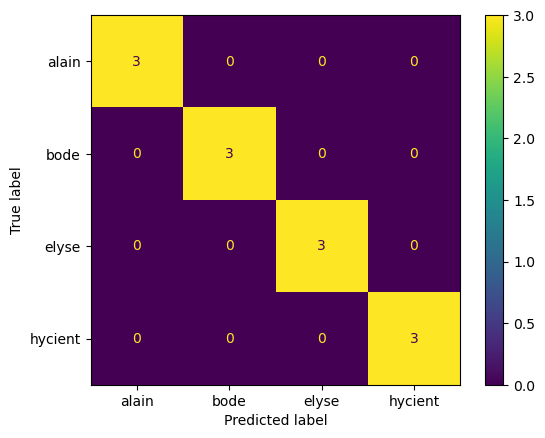

t
Present Model: logistic_regression
              precision    recall  f1-score   support

       alain       1.00      1.00      1.00         3
        bode       1.00      1.00      1.00         3
       elyse       1.00      1.00      1.00         3
     hycient       1.00      1.00      1.00         3

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



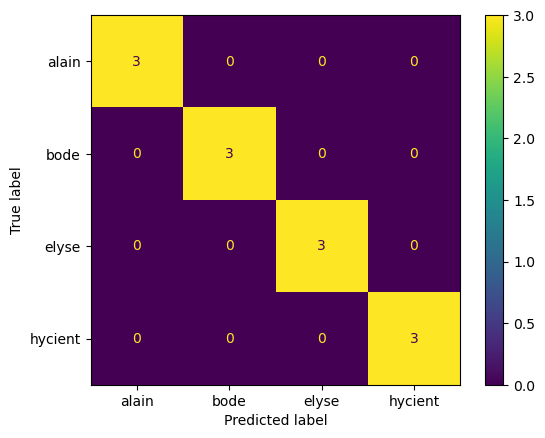

t
Present Model: knn
              precision    recall  f1-score   support

       alain       1.00      1.00      1.00         3
        bode       1.00      1.00      1.00         3
       elyse       1.00      1.00      1.00         3
     hycient       1.00      1.00      1.00         3

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



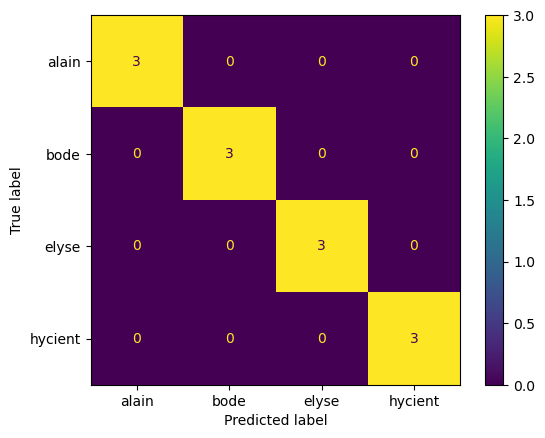

In [21]:
print("\tConfusion and other evaluation Metric")
for name, model in models.items():
    print(f"t\nPresent Model: {name}")
    choosen_model = name
    print(classification_report(y[is_original], all_predictions[choosen_model][is_original]))
    ConfusionMatrixDisplay.from_predictions(y[is_original], all_predictions[choosen_model][is_original])
    plt.show()


Macro average precision: 1.0


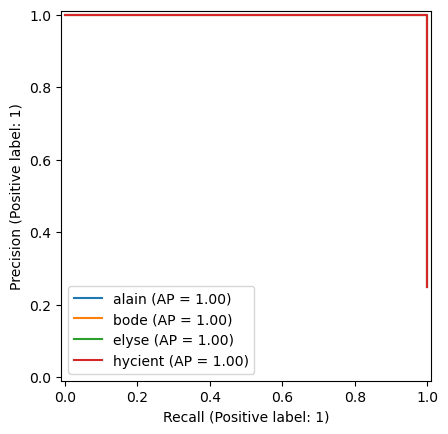

In [22]:
classes = np.unique(y)
model = models["svm"]
proba = cross_val_predict(model, X, y, groups=groups,
                          cv=LeaveOneGroupOut(), method="predict_proba")

y_true = label_binarize(y[is_original], classes=classes)
y_score = proba[is_original]

print("Macro average precision:", average_precision_score(y_true, y_score, average="macro"))

fig, ax = plt.subplots()
for k, person in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(y_true[:, k], y_score[:, k], name=person, ax=ax)
plt.show()


In [23]:
from sklearn.metrics.pairwise import cosine_similarity

originals = df[is_original]
similarities = cosine_similarity(originals.filter(like="emb_").values)
names = originals["person"].values
i, j = np.triu_indices(len(originals), k=1)
same_person = names[i] == names[j]
pair_scores = similarities[i, j]

print(f"Total pairs: {len(pair_scores)} | same person: {same_person.sum()} | different people: {(~same_person).sum()}")

Total pairs: 66 | same person: 12 | different people: 54


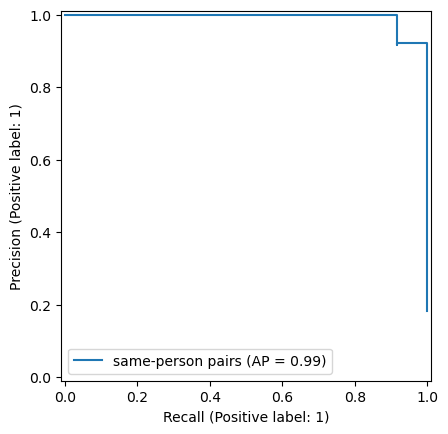

Average precision: 0.9935897435897436
ROC AUC: 0.9984567901234568


In [24]:
from sklearn.metrics import roc_auc_score

PrecisionRecallDisplay.from_predictions(same_person, pair_scores, name="same-person pairs")
plt.show()
print("Average precision:", average_precision_score(same_person, pair_scores))
print("ROC AUC:", roc_auc_score(same_person, pair_scores))


In [25]:
from sklearn.model_selection import permutation_test_score

n_permutations = 100
chance_level = 1 / len(np.unique(y))

score, perm_scores, p_value = permutation_test_score(
    SVC(kernel="linear"), X, y, groups=groups, cv=LeaveOneGroupOut(),
    n_permutations=n_permutations, random_state=SEED)

print("Permutation test: is the model learning real patterns or leaking data?")
print("-" * 70)
print(f"Accuracy with true labels:{score:.1%}")
print(f"Accuracy with shuffled labels:{perm_scores.mean():.1%} (average of {n_permutations} shuffles)")
print(f"Random guessing ({len(np.unique(y))} people):{chance_level:.1%}")
print(f"p-value:{p_value:.4f}")
print("-" * 70)

if abs(perm_scores.mean() - chance_level) < 0.10:
    print("Shuffled accuracy is close to random guessing, meaning no data leakage.")
else:
    print("Shuffled accuracy is far from random guessing, meaning possible data leakage, check the split.")

if p_value < 0.05:
    print(f"p-value < 0.05 -> the {score:.0%} accuracy is very unlikely to be luck.")
else:
    print("p-value >= 0.05 -> the accuracy could be due to chance.")

Permutation test: is the model learning real patterns or leaking data?
----------------------------------------------------------------------
Accuracy with true labels:100.0%
Accuracy with shuffled labels:24.3% (average of 100 shuffles)
Random guessing (4 people):25.0%
p-value:0.0099
----------------------------------------------------------------------
Shuffled accuracy is close to random guessing, meaning no data leakage.
p-value < 0.05 -> the 100% accuracy is very unlikely to be luck.


### Set a Threshold for face verification

Similarity check: where do the two groups meet?
----------------------------------------------------------------------
Lowest same-person score:0.580
Highest different-person score:0.587
Groups overlap -> lowest threshold that lets in no wrong person: 0.588
----------------------------------------------------------------------
Real person rejected: 8.3% (1/12 same-person pairs)
Wrong person accepted: 0.0% (0/54 different-person pairs)


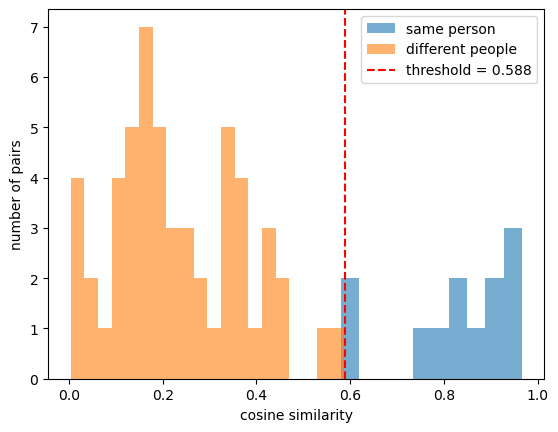

In [26]:
same_person_scores = pair_scores[same_person]
different_person_scores = pair_scores[~same_person]

lowest_same_person_score = same_person_scores.min()
highest_different_person_score = different_person_scores.max()

print("Similarity check: where do the two groups meet?")
print("-" * 70)
print(f"Lowest same-person score:{lowest_same_person_score:.3f}")
print(f"Highest different-person score:{highest_different_person_score:.3f}")

if lowest_same_person_score > highest_different_person_score:
    threshold = (lowest_same_person_score + highest_different_person_score) / 2
    print(f"Clear gap -> threshold at the midpoint: {threshold:.3f}")
else:
    candidate_thresholds = np.linspace(0, 1, 1001)
    accepted_wrong_person_rates = np.array(
        [(different_person_scores >= candidate).mean() for candidate in candidate_thresholds])
    thresholds_with_no_wrong_accepts = candidate_thresholds[accepted_wrong_person_rates == 0]
    threshold = thresholds_with_no_wrong_accepts.min()
    print(f"Groups overlap -> lowest threshold that lets in no wrong person: {threshold:.3f}")
print("-" * 70)

rejected_real_person = same_person_scores < threshold
accepted_wrong_person = different_person_scores >= threshold
print(f"Real person rejected: {rejected_real_person.mean():.1%} "
      f"({rejected_real_person.sum()}/{len(same_person_scores)} same-person pairs)")
print(f"Wrong person accepted: {accepted_wrong_person.mean():.1%} "
      f"({accepted_wrong_person.sum()}/{len(different_person_scores)} different-person pairs)")

plt.hist(same_person_scores, bins=10, alpha=0.6, label="same person")
plt.hist(different_person_scores, bins=20, alpha=0.6, label="different people")
plt.axvline(threshold, color="red", linestyle="--", label=f"threshold = {threshold:.3f}")
plt.xlabel("cosine similarity")
plt.ylabel("number of pairs")
plt.legend()
plt.show()


In [27]:
for candidate_threshold in [0.577, 0.6]:
    rejected_real_person = (same_person_scores < candidate_threshold).sum()
    accepted_wrong_person = (different_person_scores >= candidate_threshold).sum()
    print(f"threshold {candidate_threshold}: real person rejected {rejected_real_person}/{len(same_person_scores)}, "
          f"wrong person accepted {accepted_wrong_person}/{len(different_person_scores)}")

threshold 0.577: real person rejected 0/12, wrong person accepted 1/54
threshold 0.6: real person rejected 1/12, wrong person accepted 0/54


In [28]:
file_names = originals["file"].values
first_file, second_file = file_names[i], file_names[j]

pairs_table = pd.DataFrame({
    "first_photo": first_file,
    "second_photo": second_file,
    "same_person": same_person,
    "similarity": pair_scores,
})

closest_to_threshold = (pairs_table["similarity"] - threshold).abs().sort_values().index[:5]
pairs_table.loc[closest_to_threshold].round(3)


,first_photo,second_photo,same_person,similarity
60,alain_surprised.jpeg,bode_neutral.jpeg,False,0.587
31,elyse_surprised.jpg,elyse_neutral.jpeg,True,0.580
30,elyse_surprised.jpg,elyse_smiling.jpeg,True,0.614
62,alain_surprised.jpeg,bode_surprised.jpeg,False,0.530
53,alain_smiling.jpeg,bode_neutral.jpeg,False,0.458


In [29]:
final_model = models["svm"].fit(X, y)

## Test for strangers

In [30]:
# check dataset path
def get_strangers_path():
    """
    This function check for environment and return file path
    """
    if os.path.exists("/kaggle/working/"):
        dataset_path = Path("/kaggle/input/datasets/bodemmb230/strangers/strangers")
        return dataset_path
    if os.path.exists("/var/colab/hostname"):
        from google.colab import drive
        drive.mount("/content/drive")
        dataset_path = Path("/content/drive/MyDrive/datasets/strangers")
        return dataset_path
    file_path = Path.cwd()
    return file_path / "datasets" / "strangers"

dataset_path = get_strangers_path()
print(dataset_path, "exists:", dataset_path.exists())

/home/bode-murairi/Documents/programming/ml/assignments/Multimodal-Data-Preprocessing/facial_recognition/datasets/strangers exists: True


In [31]:
reference_embeddings = {}
for person_name in np.unique(y):
    person_rows = df[is_original & (df["person"] == person_name)]
    average_embedding = person_rows.filter(like="emb_").values.mean(axis=0)
    reference_embeddings[person_name] = average_embedding / np.linalg.norm(average_embedding)

print(f"Reference embeddings for: {list(reference_embeddings)}")


Reference embeddings for: ['alain', 'bode', 'elyse', 'hycient']


In [32]:
strangers_path = get_strangers_path()
stranger_files = [file for file in strangers_path.rglob("*") if file.suffix.lower() in (".jpeg", ".jpg")]
stranger_rows = pd.DataFrame(extract_embedding(images=stranger_files))
stranger_embeddings = stranger_rows.filter(like="emb_").values

for row_number, stranger_embedding in enumerate(stranger_embeddings):
    similarity_to_each_person = {
        person_name: float(stranger_embedding @ reference)
        for person_name, reference in reference_embeddings.items()
    }
    closest_person = max(similarity_to_each_person, key=similarity_to_each_person.get)
    best_similarity = similarity_to_each_person[closest_person]

    class_probabilities = final_model.predict_proba([stranger_embedding])[0]
    classifier_guess = final_model.classes_[class_probabilities.argmax()]
    highest_probability = class_probabilities.max()

    decision = "ACCEPTED (wrong!)" if best_similarity >= threshold else "rejected (correct)"

    print(f"{stranger_rows['file'][row_number]}:")
    print(f"classifier says '{classifier_guess}' with probability {highest_probability:.1%}")
    print(f"closest is {closest_person} with similarity {best_similarity:.3f} | {decision}")


christopher-campbell-rDEOVtE7vOs-unsplash.jpeg:
classifier says 'elyse' with probability 62.3%
closest is elyse with similarity 0.071 | rejected (correct)
michael-dam-mEZ3PoFGs_k-unsplash.jpeg:
classifier says 'bode' with probability 76.7%
closest is bode with similarity 0.140 | rejected (correct)
closeup-portrait-young-african-american-man.jpeg:
classifier says 'alain' with probability 84.8%
closest is alain with similarity 0.333 | rejected (correct)
serious-young-african-man-standing-isolated.jpeg:
classifier says 'elyse' with probability 94.0%
closest is bode with similarity 0.148 | rejected (correct)
beautiful-african-woman-face-portrait-close-up.jpeg:
classifier says 'elyse' with probability 81.6%
closest is elyse with similarity 0.349 | rejected (correct)
vitaly-gariev-tnoa2lIZAHk-unsplash.jpeg:
classifier says 'bode' with probability 84.9%
closest is bode with similarity 0.143 | rejected (correct)
houcine-ncib-B4TjXnI0Y2c-unsplash.jpeg:
classifier says 'elyse' with probability 9

In [33]:
saved_threshold = float(np.ceil(threshold * 20) / 20)

saved_artifacts = {
    "classifier": final_model,
    "threshold": saved_threshold,
    "reference_embeddings": reference_embeddings,
    "people": list(final_model.classes_),
}

artifacts_folder = get_output_root().parent.parent / "model"
artifacts_folder.mkdir(parents=True, exist_ok=True)
artifacts_path = artifacts_folder / "face_verification.joblib"
joblib.dump(saved_artifacts, artifacts_path)

print(f"Saved to: {artifacts_path}")
print(f"People: {saved_artifacts['people']}")
print(f"Measured threshold: {threshold:.3f}, saved threshold (rounded up): {saved_threshold:.2f}")


Saved to: /home/bode-murairi/Documents/programming/ml/assignments/Multimodal-Data-Preprocessing/facial_recognition/model/face_verification.joblib
People: ['alain', 'bode', 'elyse', 'hycient']
Measured threshold: 0.588, saved threshold (rounded up): 0.60


In [34]:
model_params = {
    "threshold": saved_threshold,
    "people": saved_artifacts["people"],
    "reference_embeddings": {
        person_name: embedding.tolist()
        for person_name, embedding in reference_embeddings.items()
    },
}

model_params_path = artifacts_folder / "model_params.json"
with open(model_params_path, "w") as json_file:
    json.dump(model_params, json_file, indent=2)

print(f"Saved readable parameters to: {model_params_path}")


Saved readable parameters to: /home/bode-murairi/Documents/programming/ml/assignments/Multimodal-Data-Preprocessing/facial_recognition/model/model_params.json
